# EDA of the Football Players Detection Dataset

We explore the YOLO bounding-box dataset splits, class distribution, label integrity, box dimensions, and feature relationships. Feature engineering here is descriptive; it does not alter the original labels.

**Data Source:** Roboflow football-players-detection, v1, YOLOv5 export. License: CC BY 4.0. Source: [Roboflow Universe](https://universe.roboflow.com/roboflow-jvuqo/football-players-detection-3zvbc/dataset/1). Train/validation/test splits are preserved as provided in the dataset.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

project_root = Path.cwd().resolve()
while not (project_root / "src" / "football_dataset.py").is_file():
    if project_root.parent == project_root:
        raise FileNotFoundError("Could not locate the project src/ directory from the notebook working directory.")
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))

from football_dataset import load_dataset_spec, scan_yolo_dataset

default_root = Path.home() / "Downloads" / "football-players-detection.v1i.yolov5pytorch"
dataset_root = Path(os.environ.get("FOOTBALL_DATASET_ROOT", default_root)).expanduser().resolve()
print(f"Dataset: {dataset_root}")

Dataset: /Users/koryunsirunyan/Downloads/football-players-detection.v1i.yolov5pytorch


## 1. Integrity Check

Each YOLO label row must contain `class_id, center_x, center_y, width, height` fields. Coordinates and dimensions are normalized within the [0, 1] range. An empty label file may indicate a background image, so it is counted separately from a missing label file.

In [3]:
annotations, audit, class_names = scan_yolo_dataset(dataset_root)
display(audit)
print(f"classes {class_names}")
print(f"bounding boxes՝ {len(annotations):,}")
display(annotations.isna().sum().rename("missing values").to_frame())

,split,images,label_files,missing_label_files,empty_label_files,orphan_label_files,invalid_rows,valid_boxes
0,train,612,612,0,0,0,0,14583
1,val,38,38,0,0,0,0,905
2,test,13,13,0,0,0,0,310


classes ['ball', 'goalkeeper', 'player', 'referee']
bounding boxes՝ 15,798


,missing values
split,0
image,0
label_line,0
class_id,0
class_name,0
center_x,0
center_y,0
width,0
height,0
area,0


## 2. Class and Split Distribution

Class counts illustrate class imbalance. Results from small validation/test splits should be interpreted with caution; they can fluctuate significantly due to the small number of images.

class_name,ball,goalkeeper,player,referee
split,,,,
test,11,11,259,29
train,519,435,12228,1401
val,35,27,754,89


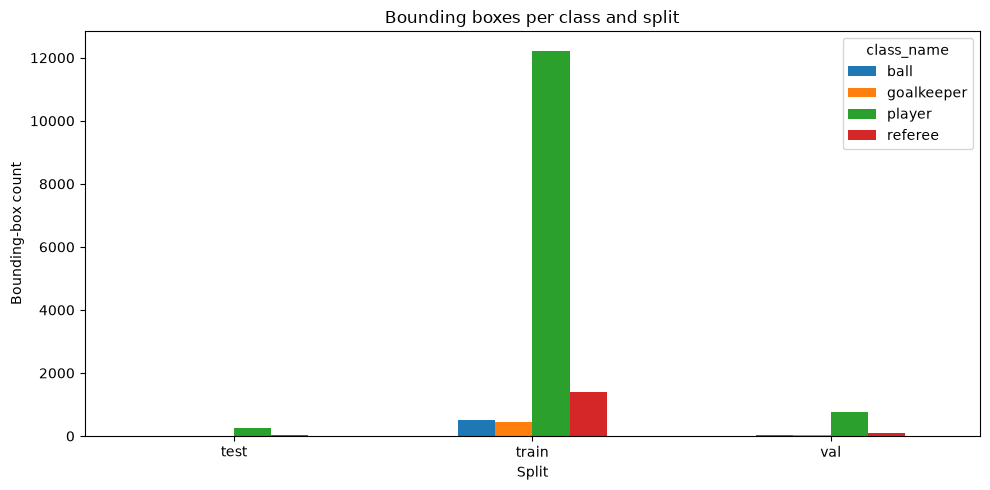

In [3]:
class_counts = (
    annotations.groupby(["split", "class_name"]).size()
    .unstack(fill_value=0)
    .reindex(columns=class_names, fill_value=0)
)
display(class_counts)
ax = class_counts.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_title("Bounding boxes per class and split")
ax.set_xlabel("Split")
ax.set_ylabel("Bounding-box count")
plt.tight_layout()
plt.show()

## 3. Size Distribution and Feature Engineering

Features like `area = width × height`, `aspect_ratio = width / height`, and `vertical_zone` are derived from the initial bounding boxes. The thresholds for `relative_scale` are conditional, descriptive groupings rather than ground-truth labels for model training.

width                                                          \
              count    mean     std     min     25%     50%     75%     max   
class_name                                                                    
ball          565.0  0.0059  0.0014  0.0031  0.0049  0.0057  0.0066  0.0125   
goalkeeper    473.0  0.0123  0.0029  0.0057  0.0104  0.0120  0.0141  0.0219   
player      13241.0  0.0135  0.0048  0.0001  0.0099  0.0125  0.0159  0.0391   
referee      1519.0  0.0130  0.0060  0.0051  0.0089  0.0109  0.0146  0.0434   

             height          ... center_x         center_y                  \
              count    mean  ...      75%     max    count    mean     std   
class_name                   ...                                             
ball          565.0  0.0110  ...   0.6625  0.9807    565.0  0.4417  0.1450   
goalkeeper    473.0  0.0447  ...   0.8599  0.9969    473.0  0.3882  0.0665   
player      13241.0  0.0522  ...   0.6654  0.9883  13241.0  0.4344  0.1275   
referee      1519.0  0.0502  ...   0.6332  0.9919   1519.0  0.4258  0.2044   

                                                    
               min     25%     50%     75%     max  
class_name                                          
ball        0.0427  0.3239  0.4185  0.5463  0.8080  
goalkeeper  0.2694  0.3431  0.3819  0.4237  0.8329  
player      0.0894  0.3435  0.4208  0.5130  0.9852  
referee     0.0671  0.2815  0.3681  0.4801  0.9852  

[4 rows x 48 columns]

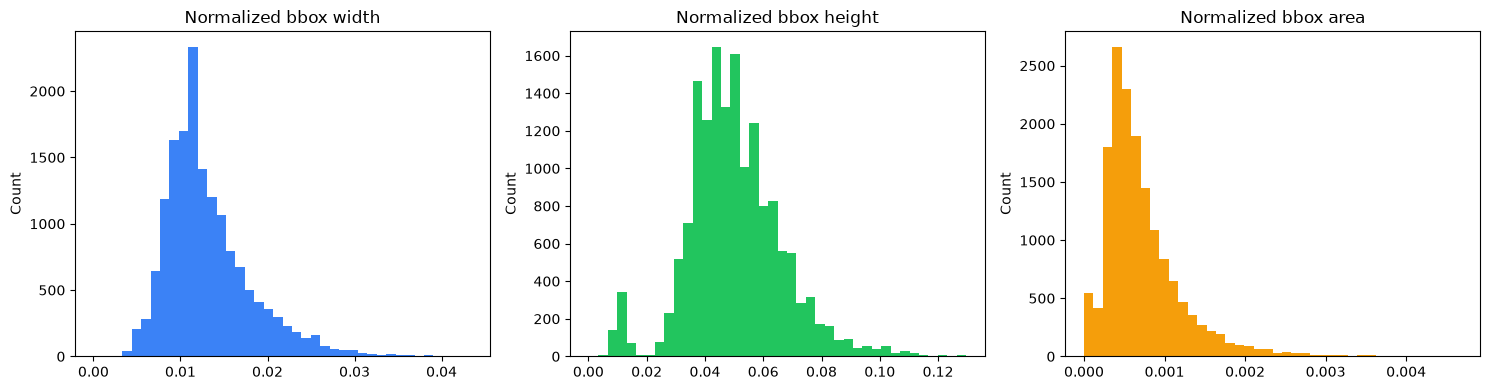

relative_scale,large,medium,small
class_name,,,
ball,0,0,565
goalkeeper,3,269,201
player,885,7746,4610
referee,191,567,761


vertical_zone,lower,middle,upper
class_name,,,
ball,42,373,150
goalkeeper,3,381,89
player,678,9601,2962
referee,238,709,572


In [4]:
feature_columns = ["width", "height", "area", "aspect_ratio", "center_x", "center_y"]
display(annotations.groupby("class_name")[feature_columns].describe().round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(annotations["width"], bins=40, color="#3b82f6")
axes[0].set_title("Normalized bbox width")
axes[1].hist(annotations["height"], bins=40, color="#22c55e")
axes[1].set_title("Normalized bbox height")
axes[2].hist(annotations["area"], bins=40, color="#f59e0b")
axes[2].set_title("Normalized bbox area")
for axis in axes:
    axis.set_ylabel("Count")
plt.tight_layout()
plt.show()

display(pd.crosstab(annotations["class_name"], annotations["relative_scale"]))
display(pd.crosstab(annotations["class_name"], annotations["vertical_zone"]))

## 4. Feature Relationships

Correlation is calculated between continuous, normalized bounding-box features. `class_id` is not a numerical quantity and is not included in the correlation matrix. The relationship does not imply causality.

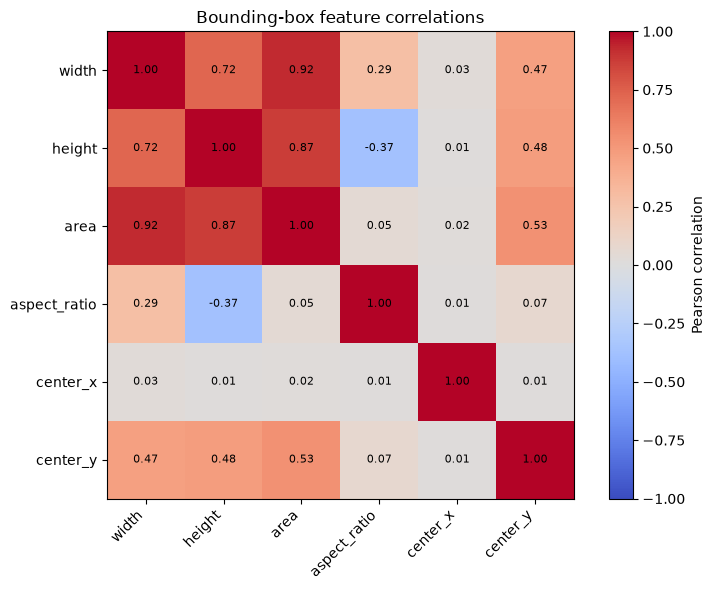

,width,height,area,aspect_ratio,center_x,center_y
width,1.000,0.721,0.924,0.286,0.025,0.468
height,0.721,1.000,0.873,-0.367,0.014,0.481
area,0.924,0.873,1.000,0.053,0.020,0.534
aspect_ratio,0.286,-0.367,0.053,1.000,0.011,0.070
center_x,0.025,0.014,0.020,0.011,1.000,0.013
center_y,0.468,0.481,0.534,0.070,0.013,1.000


In [5]:
correlations = annotations[feature_columns].corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)), correlations.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlations.index)), correlations.index)
for row in range(len(correlations.index)):
    for column in range(len(correlations.columns)):
        ax.text(column, row, f"{correlations.iloc[row, column]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(image, ax=ax, label="Pearson correlation")
ax.set_title("Bounding-box feature correlations")
plt.tight_layout()
plt.show()
display(correlations.round(3))

## 5. Visual Inspection of Labels

YOLO bounding boxes are drawn on several training images. This helps detect incorrect classes, faulty normalization, or label/image mismatches.

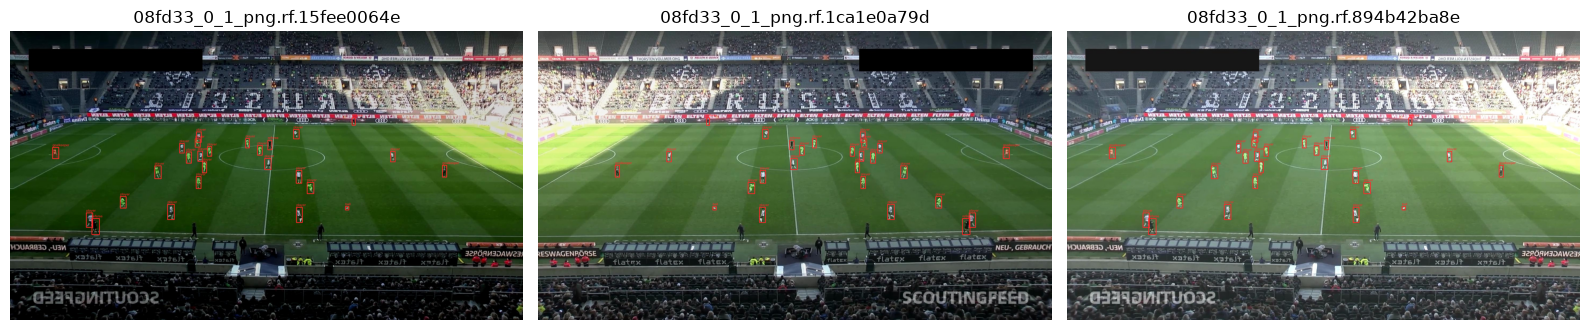

In [7]:
import cv2

_, _, split_paths = load_dataset_spec(dataset_root)
sample_images = sorted(split_paths["train"].glob("*.jpg"))[:3]
fig, axes = plt.subplots(1, len(sample_images), figsize=(16, 5))
if len(sample_images) == 1:
    axes = [axes]
for axis, image_path in zip(axes, sample_images):
    image = cv2.imread(str(image_path))
    if image is None:
        raise OSError(f"Could not read image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]
    label_path = image_path.parent.parent / "labels" / f"{image_path.stem}.txt"
    if label_path.is_file():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            class_id = int(parts[0])
            center_x, center_y, box_width, box_height = map(float, parts[1:])
            x1 = int((center_x - box_width / 2) * width)
            y1 = int((center_y - box_height / 2) * height)
            x2 = int((center_x + box_width / 2) * width)
            y2 = int((center_y + box_height / 2) * height)
            cv2.rectangle(image, (x1, y1), (x2, y2), (255, 40, 40), 2)
            cv2.putText(image, class_names[class_id], (x1, max(16, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 40, 40), 1)
    axis.imshow(image)
    axis.set_title(image_path.name[:28])
    axis.axis("off")
plt.tight_layout()
plt.show()